# DX 602 Final Project

## Introduction

In this project, you will practice the skills that you have learned throughout this module with a heavy focus on building models.
Most of the problems and questions are open ended compared to your previous homeworks, and you will be asked to explain your choices.
Most of them will have a particular type of solution implied, but it is up to you to figure out the details based on what you have learned in this module.

## Instructions

Each problem asks you to perform build models, run a computation, or otherwise perform some analysis of the data, and usually answer some questions about the results.
Make sure that your question answers are well supported by your analysis and explanations; simply stating an answer without support will earn minimal points.

Notebook cells for code and text have been added for your convenience, but feel free to add additional cells.

## Example Code

You may find it helpful to refer to this GitHub repository of Jupyter notebooks for example code.

* https://github.com/bu-cds-omds/dx601-examples
* https://github.com/bu-cds-omds/dx602-examples

Any calculations demonstrated in code examples or videos may be found in these notebooks, and you are allowed to copy this example code in your homework answers.

## Submission

This project will be entirely manually graded.
However, we may rerun some or all of your code to confirm that it works as described.

### Late Policy

The normal homework late policy for OMDS does not apply to this project.
Boston University requires final grades to be submitted within 72 hours of class instruction ending, so we cannot accommodate 5 days of late submissions.

However, we have delayed the due date of this project to be substantially later than necessary given its scope, and given you more days for submission with full credit than you would have had days for submission with partial credit under the homework late policy.
The Thanksgiving holiday was also taken into account in setting the deadline.
Finally, the deadlines for DX 601 and DX 602 were coordinated to be a week apart while giving ample time for both of their projects.

## Shared Imports

For this project, you are forbidden to use modules that were not loaded in this template.
While other modules are handy in practice, modules that trivialize these problems interfere with our assessment of your own knowledge and skills.

If you believe a module covered in the course material (not live sessions) is missing, please check with your learning facilitator.

In [1]:
import math
import sys

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats
import sklearn.linear_model

## Added Imports ##
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import sklearn.metrics
from sklearn.model_selection import cross_validate
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline

## Problems

### Problem 1 (5 points)

Pick one of the following data sets to analyze in this project.
Load the data set, and show a random sample of 10 rows.

* [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) ([PMLB - red subset only](https://github.com/EpistasisLab/pmlb/tree/master/datasets/wine_quality_red))
* [Body Fat](https://www.openml.org/search?type=data&status=active&id=560) ([PMLB](https://github.com/EpistasisLab/pmlb/tree/master/datasets/560_bodyfat))

The PMLB copies of the data are generally cleaner and recommended for this project, but the other links are provided to give you more context.
To load the data from the PMLB Github repository, navigate to the `.tsv.gz` file in GitHub and copy the link from the "Raw" button.

If the dataset has missing data, you should drop the rows with missing data before proceeding.
If the data set you choose has more than ten columns, you may limit later analysis that is requested per column to just the first ten columns.

In [4]:
# YOUR CODE HERE

# Load data #
"""
Loading Wine Quality data from url:
https://github.com/EpistasisLab/pmlb/raw/refs/heads/master/datasets/wine_quality_red/wine_quality_red.tsv.gz
"""

url = 'https://github.com/EpistasisLab/pmlb/raw/refs/heads/master/datasets/wine_quality_red/wine_quality_red.tsv.gz'

df = pd.read_csv(url, delimiter='\t')

# Preprocessing #
"""
Dropping all rows that have N/A value
"""
df = df.dropna()

df.sample(n=10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,target
223,8.6,0.645,0.25,2.0,0.083,8.0,28.0,0.99815,3.28,0.60,10.0,6
645,7.8,0.640,0.10,6.0,0.115,5.0,11.0,0.99840,3.37,0.69,10.1,7
1371,7.5,0.580,0.56,3.1,0.153,5.0,14.0,0.99476,3.21,1.03,11.6,6
599,12.7,0.590,0.45,2.3,0.082,11.0,22.0,1.00000,3.00,0.70,9.3,6
1462,6.8,0.640,0.03,2.3,0.075,14.0,31.0,0.99545,3.36,0.58,10.4,6
519,7.3,0.365,0.49,2.5,0.088,39.0,106.0,0.99660,3.36,0.78,11.0,5
1394,6.4,0.570,0.14,3.9,0.070,27.0,73.0,0.99669,3.32,0.48,9.2,5
361,8.6,0.450,0.31,2.6,0.086,21.0,50.0,0.99820,3.37,0.91,9.9,6
30,6.7,0.675,0.07,2.4,0.089,17.0,82.0,0.99580,3.35,0.54,10.1,5
1151,6.1,0.580,0.23,2.5,0.044,16.0,70.0,0.99352,3.46,0.65,12.5,6


YOUR ANSWERS HERE

### Problem 2 (10 points)

List all of the columns and describe them in your own words.

'\nfixed acidity (float64): This column refers to the volume of tartaric acid in the wine.\n    The distribution appears to be normal with a right-skew.\nvolatile acidity (float64): This column refers to the volume of acetic acid in the wine.\n    The distribution appears to be bimodal with a right-skew.\ncitric acid (float64): This column refers to the volume of citric acid in the wine.\n    The distribution appears to be normal with a right-skew, with a lot more variation than previous columns.\nresidual sugar (float64): This column refers to the volume of sugar leftover in the wine following fermentation.\n    The distribution appears to be normal with a right-skew.\nchlorides (float64): This column refers to the volume of sodium chloride (salt) in the wine.\n    The distribution appears to be normal with a right-skew.\nfree sulfur dioxide (float64): This column refers to the volume of sulfur dioxide in the wine that is available to\n    preserve the wine.\n    The distribution appe

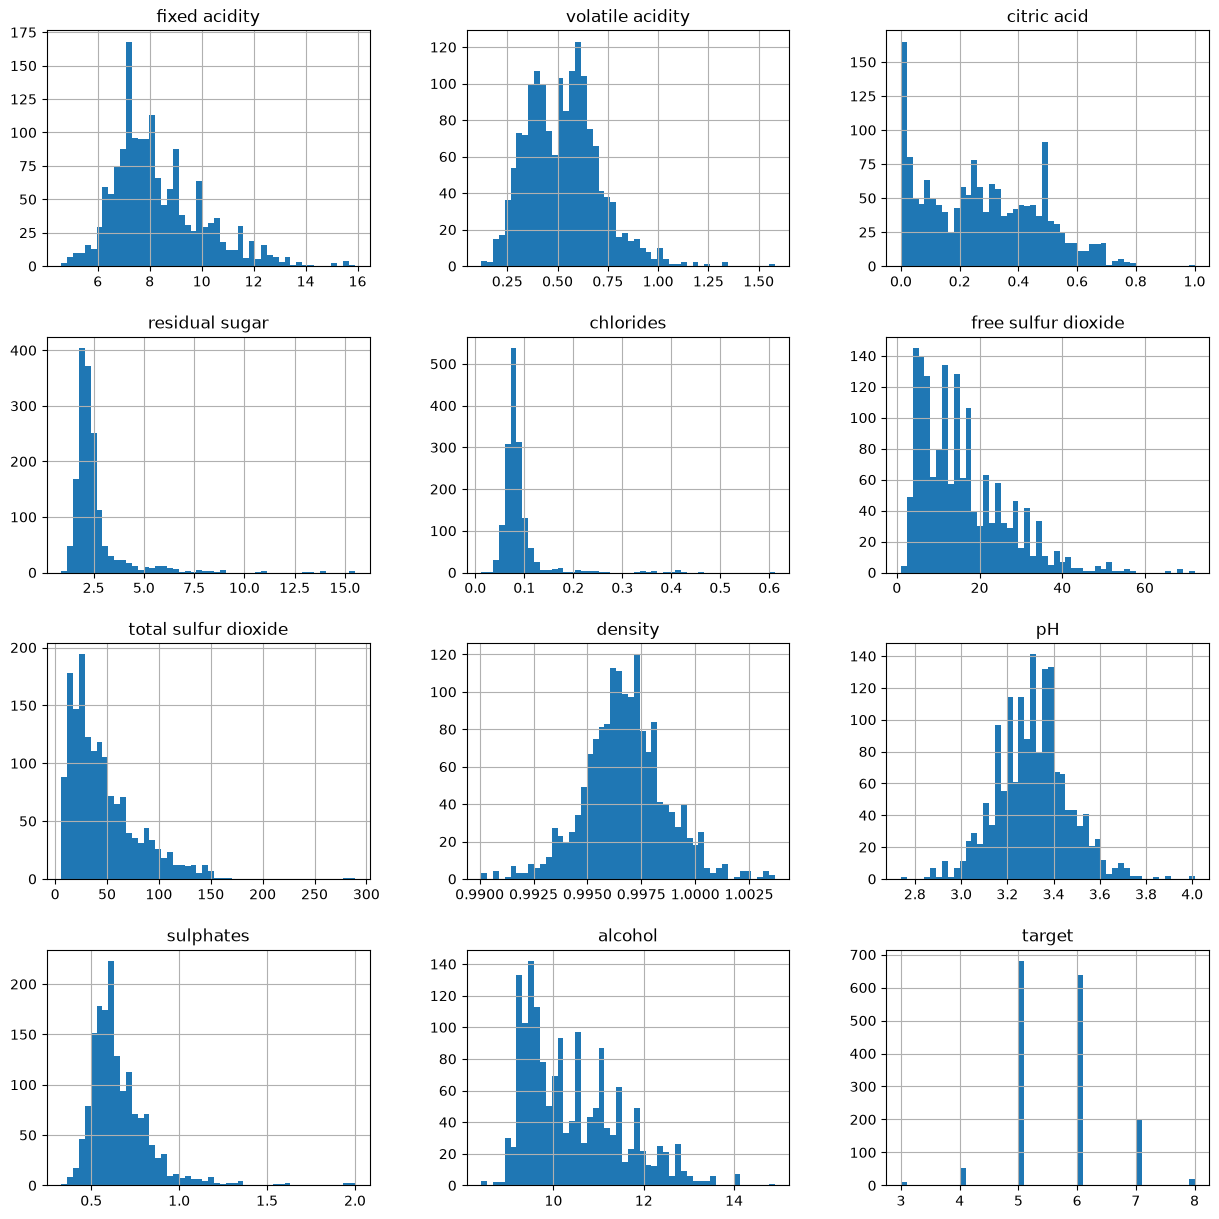

In [5]:
# YOUR CODE HERE

columns = list(df.columns)

types = list(df.dtypes)

"""
for i in range(len(columns)):
    print(f"{columns[i]}: {types[i]}")
"""

df.hist(bins=50, figsize=(15, 15))

# Columns #
"""
fixed acidity (float64): This column refers to the volume of tartaric acid in the wine.
    The distribution appears to be normal with a right-skew.
volatile acidity (float64): This column refers to the volume of acetic acid in the wine.
    The distribution appears to be bimodal with a right-skew.
citric acid (float64): This column refers to the volume of citric acid in the wine.
    The distribution appears to be normal with a right-skew, with a lot more variation than previous columns.
residual sugar (float64): This column refers to the volume of sugar leftover in the wine following fermentation.
    The distribution appears to be normal with a right-skew.
chlorides (float64): This column refers to the volume of sodium chloride (salt) in the wine.
    The distribution appears to be normal with a right-skew.
free sulfur dioxide (float64): This column refers to the volume of sulfur dioxide in the wine that is available to
    preserve the wine.
    The distribution appears to be normal with a right-skew.
total sulfur dioxide (float64): This column refers to the total volume of all the sulfur dioxide in the wine.
    The distribution appears to be normal with a right-skew.
density (float64): This column refers to the density of the wine.
    The distribution appears to be normal.
pH (float64): This column refers to the the pH of the wine.
    The distribution appears to be normal.
sulphates (float64): This column refers to the volume of potassium sulphate in the wine.
    The distribution appears to be normal with a right-skew.
alcohol (float64): This column refers to the alcohol percentage of the wine.
    The distribution appears to be normal with a right-skew.
target (int64): This column is categorical and most likely aligns to a taste rating.
    The distribution (as well as the type) demonstrates that this column is discrete values and not continuous.
"""

YOUR ANSWERS HERE

### Problem 3 (50 points)

Perform an exploratory analysis of the data set.
After your exploratory analysis, pick 3 individual charts that you the think were particularly interesting.
Repeat those charts separately from your original analysis, and after each of those charts, explain what you thought was noteworthy.

'\nThis chart plots two features against each other as well: pH vs fixed acidity.\nThere is a strong negative correlation present between these two features.\n'

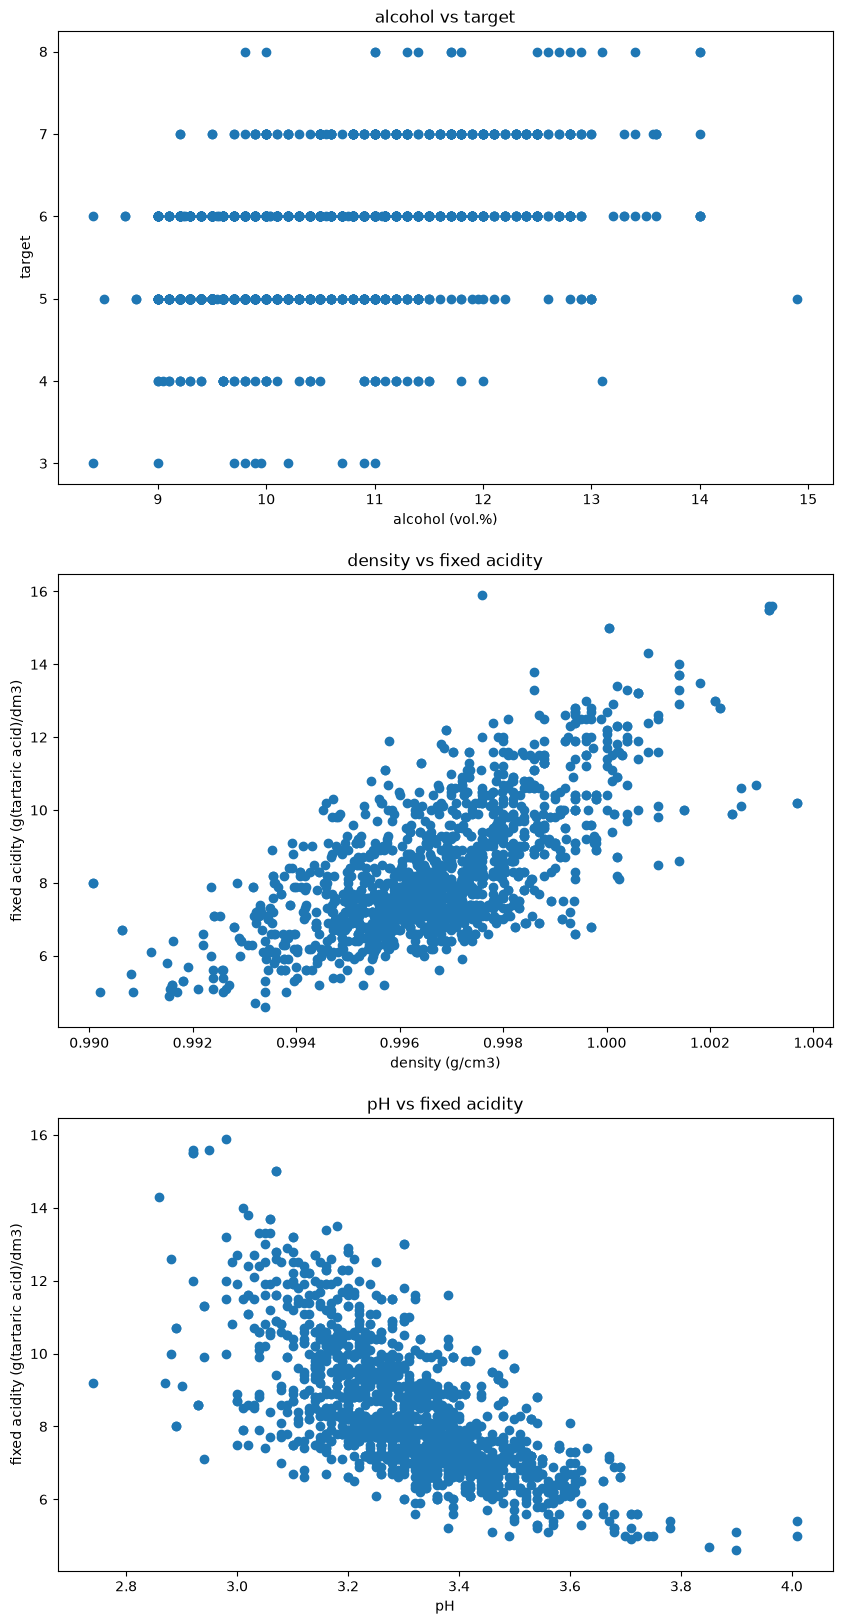

In [6]:
# YOUR CODE HERE

df_input = df.drop('target', axis=1)
df_target = df['target']

########################
# Exploratory Analysis #
########################

# plotting all input columns against target #
"""
plt.figure(figsize=(25, 45))
for i, input_col in enumerate(df_input.columns, 1):
    plt.subplot(6, 2, i)
    plt.scatter(df[input_col], df_target)
    plt.xlabel(input_col)
    plt.ylabel('target')
    plt.title(f'{input_col} vs target')
plt.tight_layout()
plt.show()
"""

# plotting all input columns against each other #
"""
pd.plotting.scatter_matrix(df_input, figsize=(12, 12), alpha=0.8)
"""

# two variables against target #
"""
pd.plotting.scatter_matrix(df_input, c=df['target'])
"""

# principal component analysis #
"""
color_map = {
    3: "red",
    4: "orange",
    5: "yellow",
    6: "green",
    7: "blue",
    8: "indigo"
}

scaler = StandardScaler()
df_input_norm = scaler.fit_transform(df_input)

normalized_pca = PCA()

projected = normalized_pca.fit_transform(df_input_norm)

for target_value, color in color_map.items():
    mask = df['target'] == target_value
    plt.scatter(projected[mask, 0], projected[mask, 1], 
                alpha=0.4, c=color, label=target_value)

plt.xlabel(f"PC1 ({normalized_pca.explained_variance_ratio_[0]:.2%} variance)")
plt.ylabel(f"PC2 ({normalized_pca.explained_variance_ratio_[1]:.2%} variance)")
plt.legend()
plt.show()
"""

# Chart 1 #
plt.figure(figsize=(10, 20))
plt.subplot(3, 1, 1)
plt.scatter(df['alcohol'], df_target)
plt.xlabel('alcohol (vol.%)')
plt.ylabel('target')
plt.title('alcohol vs target')

# Chart 2 #
plt.subplot(3, 1, 2)
plt.scatter(df['density'], df['fixed acidity'])
plt.xlabel('density (g/cm3)')
plt.ylabel('fixed acidity (g(tartaric acid)/dm3)')
plt.title('density vs fixed acidity')

# Chart 3 #
plt.subplot(3, 1, 3)
plt.scatter(df['pH'], df['fixed acidity'])
plt.xlabel('pH')
plt.ylabel('fixed acidity (g(tartaric acid)/dm3)')
plt.title('pH vs fixed acidity')

############
# Analysis #
############

# Chart 1
"""
This chart plots a single feature, alcohol, against the target.
Alcohol was chosen in this instance because it has the strongest correlation
to the target out of any individual feature.
"""

# Chart 2 #
"""
This chart plots two features against each other: density and fixed acidity.
These two features have a strong correlation which is interesting for a number of reasons.
If we had limitations on computation, we could possible cut one as they contribute
similarly.
"""

# Chart 3 #
"""
This chart plots two features against each other as well: pH vs fixed acidity.
There is a strong negative correlation present between these two features.
"""

YOUR ANSWERS HERE

### Problem 4 (5 points)

Plot the correlation matrix of the numeric columns in the data set.
Which pair of different columns were highlighted as the most correlated?

'\nFrom this correlation heatmap, a number of column pairs stand out as being particularly correlated:\n1. citric acid and fixed acidity (~0.67)\n2. fixed acidity and density (~0.67)\n3. total sulfur dioxide and free sulfur dioxide (~0.67)\n4. fixed acidity and pH (~-0.68) (negative correlation)\n'

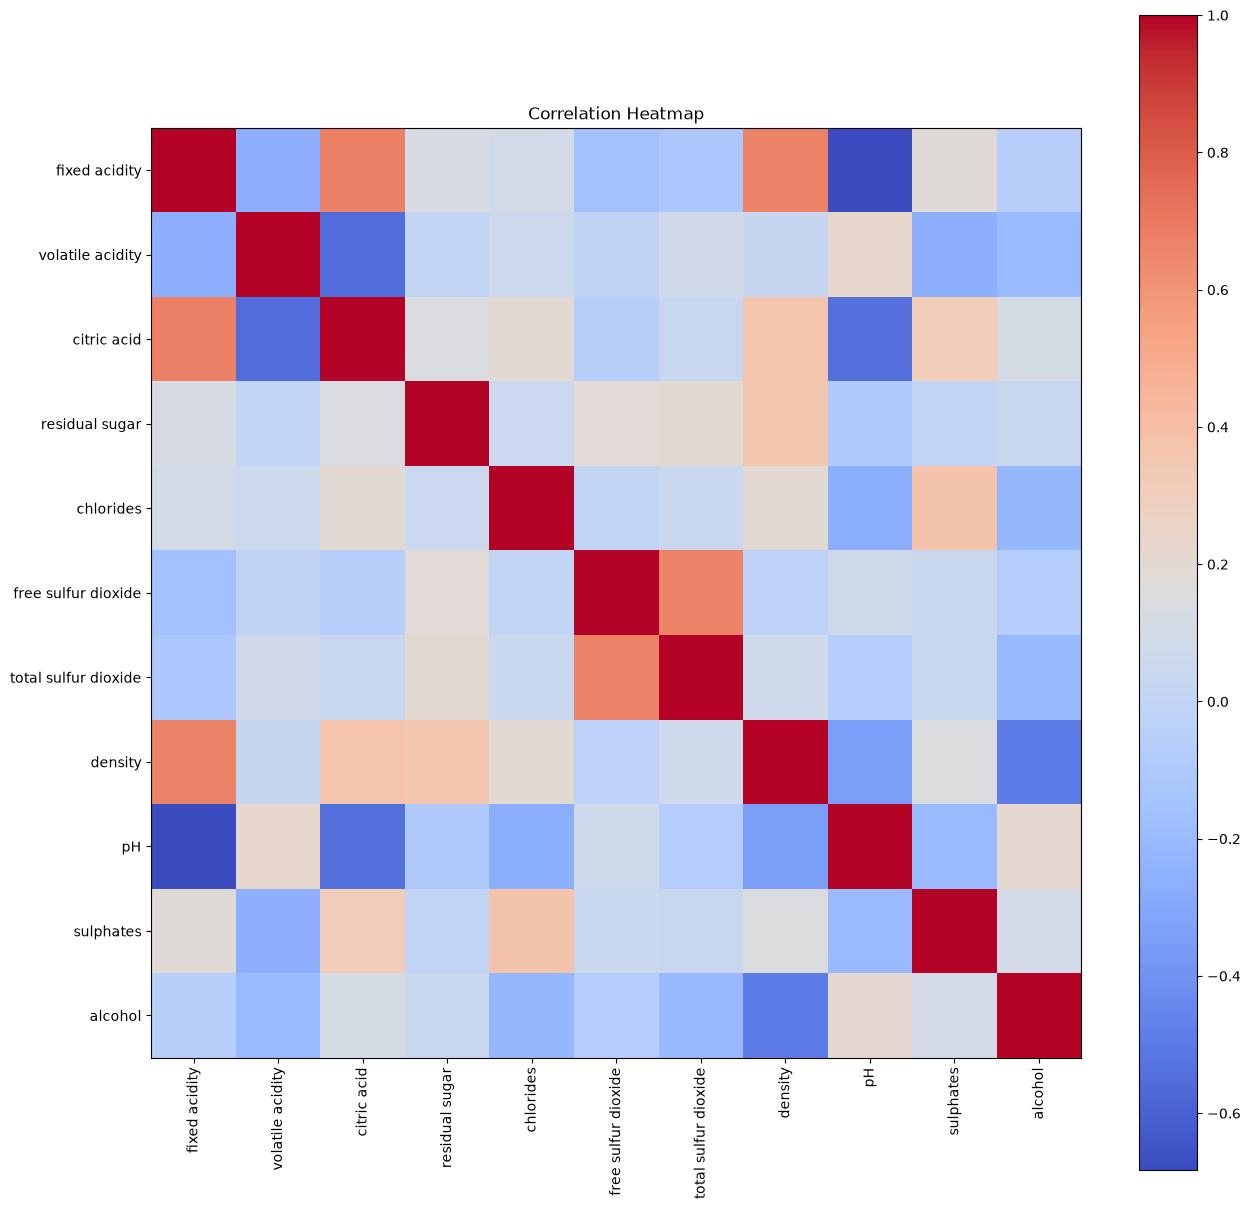

In [7]:
# YOUR CODE HERE

#print(df_input.corr())

plt.figure(figsize=(15, 15))
plt.imshow(df_input.corr(), cmap='coolwarm')
plt.xticks(range(len(df_input.corr().columns)), df_input.corr().columns, rotation=90)
plt.yticks(range(len(df_input.corr().columns)), df_input.corr().columns)
plt.colorbar()
plt.title('Correlation Heatmap')

# Analysis #
"""
From this correlation heatmap, a number of column pairs stand out as being particularly correlated:
1. citric acid and fixed acidity (~0.67)
2. fixed acidity and density (~0.67)
3. total sulfur dioxide and free sulfur dioxide (~0.67)
4. fixed acidity and pH (~-0.68) (negative correlation)
"""

YOUR ANSWERS HERE

### Problem 5 (10 points)

Pick three different regression model classes to try in problem 6 from the scikit-learn documentation.
For each class, provide a link to the scikit-learn documentation, and a link to another web page describing how that kind of model works.
The second link should not be from scikit-learn, but Wikipedia is acceptable.
You do not need to understand the methods at this time, but it is good to be comfortable researching them.

In [8]:
# YOUR CODE HERE

#####################
# Regression Models #
#####################

# Ordinary Least Squares #
"""
scikit-learn documentation: https://scikit-learn.org/stable/modules/linear_model.html#ordinary-least-squares
link: https://en.wikipedia.org/wiki/Ordinary_least_squares
"""

# Ridge #
"""
scikit-learn documentation: https://scikit-learn.org/stable/modules/linear_model.html#ridge-regression-and-classification
link: https://en.wikipedia.org/wiki/Ridge_regression
"""

# Lasso #
"""
scikit-learn documentation: https://scikit-learn.org/stable/modules/linear_model.html#lasso
link: https://www.ibm.com/think/topics/lasso-regression
"""

'\nscikit-learn documentation: https://scikit-learn.org/stable/modules/linear_model.html#lasso\nlink: https://www.ibm.com/think/topics/lasso-regression\n'

YOUR ANSWERS HERE

### Problem 6 (50 points)

Build three different regression models using the entire data set.
Plot the actual target vs the predicted values for each in one chart.
Compute the L2 and L1 losses for each of them.
You may use any regression class provided provided by scikit-learn, and you may reuse one class as long as you change its parameters enough to see different results.

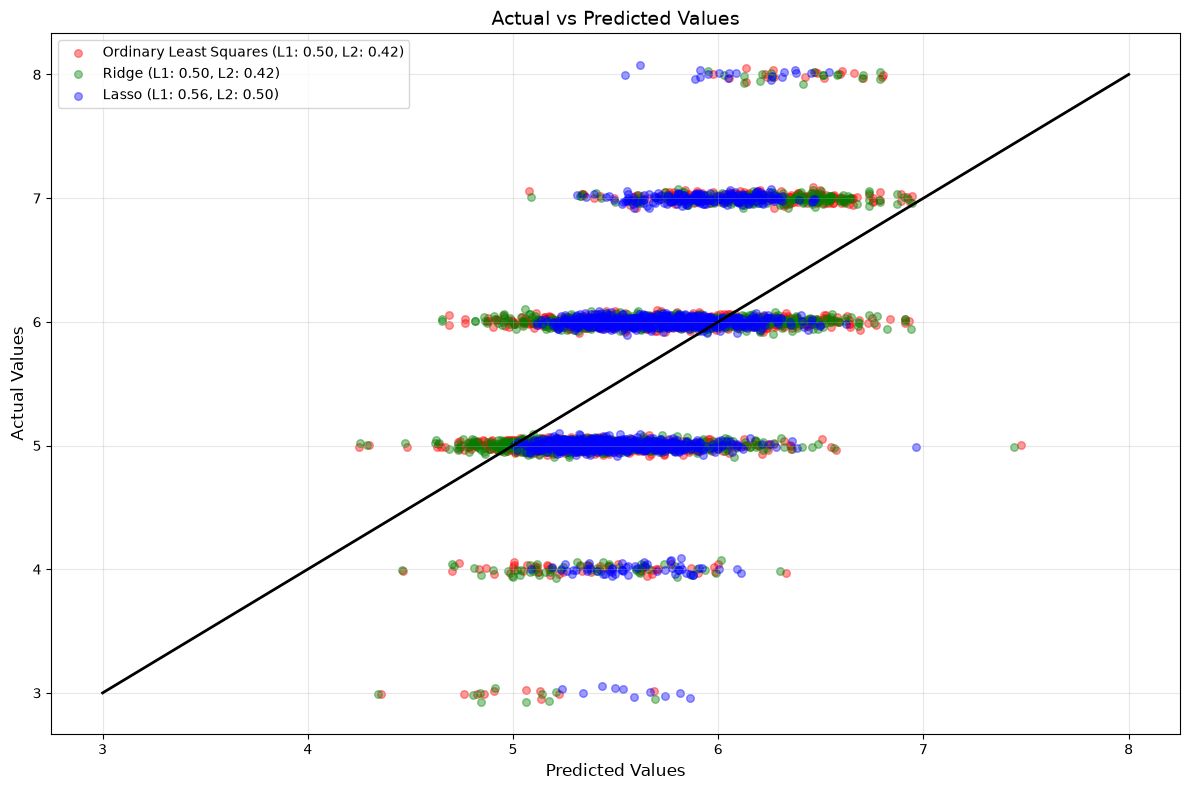

In [9]:
# YOUR CODE HERE

# Defining models
model_ols = sklearn.linear_model.LinearRegression()
model_ridge = sklearn.linear_model.Ridge(alpha=.5)
model_lasso = sklearn.linear_model.Lasso(alpha=0.1)

# Fitting
model_ols.fit(df_input, df_target)
model_ridge.fit(df_input, df_target)
model_lasso.fit(df_input, df_target)

# Predicting
pred_ols = model_ols.predict(df_input)
pred_ridge = model_ridge.predict(df_input)
pred_lasso = model_lasso.predict(df_input)

# Losses
l2_ols = sklearn.metrics.mean_squared_error(df_target, pred_ols)
l1_ols = sklearn.metrics.mean_absolute_error(df_target, pred_ols)

l2_ridge = sklearn.metrics.mean_squared_error(df_target, pred_ridge)
l1_ridge = sklearn.metrics.mean_absolute_error(df_target, pred_ridge)

l2_lasso = sklearn.metrics.mean_squared_error(df_target, pred_lasso)
l1_lasso = sklearn.metrics.mean_absolute_error(df_target, pred_lasso)

# Plotting
plt.figure(figsize=(12, 8))

jitter_ols = np.random.normal(0, 0.03, size=len(df_target))
jitter_ridge = np.random.normal(0, 0.03, size=len(df_target))
jitter_lasso = np.random.normal(0, 0.03, size=len(df_target))

plt.scatter(pred_ols,
            df_target + jitter_ols,
            alpha=0.4,
            s=30,
            color='red',
            label=f"Ordinary Least Squares (L1: {l1_ols:.2f}, L2: {l2_ols:.2f})"
)
plt.scatter(pred_ridge,
            df_target + jitter_ridge,
            alpha=0.4,
            s=30,
            color='green',
            label=f"Ridge (L1: {l1_ridge:.2f}, L2: {l2_ridge:.2f})"
)
plt.scatter(pred_lasso,
            df_target + jitter_lasso,
            alpha=0.4,
            s=30,
            color='blue',
            label=f"Lasso (L1: {l1_lasso:.2f}, L2: {l2_lasso:.2f})"
)

min_val = min(pred_ols.min(), pred_ridge.min(), pred_lasso.min(), df_target.min())
max_val = max(pred_ols.max(), pred_ridge.max(), pred_lasso.max(), df_target.max())
plt.plot([min_val, max_val], [min_val, max_val], lw=2, color='black')

plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Actual Values', fontsize=12)
plt.title('Actual vs Predicted Values', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

YOUR ANSWERS HERE

### Problem 7 (30 points)

Use 5-fold cross-validation to repeat building the same three kinds of regression models. Compare the L2 losses predicted by cross-validation against the L2 losses training against the whole data set. (The difference is likely from overfitting in the latter.)

In [10]:
# YOUR CODE HERE

# 5-fold cross-validation
kf = KFold(n_splits=5)

# Defining models
model_ols_kf = sklearn.linear_model.LinearRegression()
model_ridge_kf = sklearn.linear_model.Ridge(alpha=.5)
model_lasso_kf = sklearn.linear_model.Lasso(alpha=0.1)

# Training
l2_dict = {
    'ols': [],
    'ridge': [],
    'lasso': []
}

for train, test in kf.split(df_input):
    model_ols_kf.fit(df_input.iloc[train], df_target.iloc[train])
    model_ridge_kf.fit(df_input.iloc[train], df_target.iloc[train])
    model_lasso_kf.fit(df_input.iloc[train], df_target.iloc[train])

    pred_ols_kf = model_ols_kf.predict(df_input.iloc[test])
    pred_ridge_kf = model_ridge_kf.predict(df_input.iloc[test])
    pred_lasso_kf = model_lasso_kf.predict(df_input.iloc[test])

    l2_ols_kf = sklearn.metrics.mean_squared_error(df_target.iloc[test], pred_ols_kf)
    l2_ridge_kf = sklearn.metrics.mean_squared_error(df_target.iloc[test], pred_ridge_kf)
    l2_lasso_kf = sklearn.metrics.mean_squared_error(df_target.iloc[test], pred_lasso_kf)

    l2_dict['ols'].append(l2_ols_kf)
    l2_dict['ridge'].append(l2_ridge_kf)
    l2_dict['lasso'].append(l2_lasso_kf)

for key, values in l2_dict.items():
    if key == 'ols':
        print('Ordinary Least Squares Regression')
    elif key == 'ridge':
        print('Ridge Regression')
    elif key == 'lasso':
        print('Lasso Regression')
    print(f"Mean L2: {np.mean(values):.2f}")

########################
# L2 losses comparison #
########################
"""
The L2 losses are higher than when computed using a model trained on the whole dataset.
"""

Ordinary Least Squares Regression
Mean L2: 0.44
Ridge Regression
Mean L2: 0.44
Lasso Regression
Mean L2: 0.51


'\nThe L2 losses are higher than when computed using a model trained on the whole dataset.\n'

YOUR ANSWERS HERE

### Problem 8 (25 points)

Build three different regression models as in problem 6, but preprocess the data so that each column has mean zero and standard deviation one first.
For full credit, use a scikit-learn pipeline for each model.
For each model, compare the L2 losses -- which of them performed differently from your results in problem 6?

(This process will be covered in week 13.)

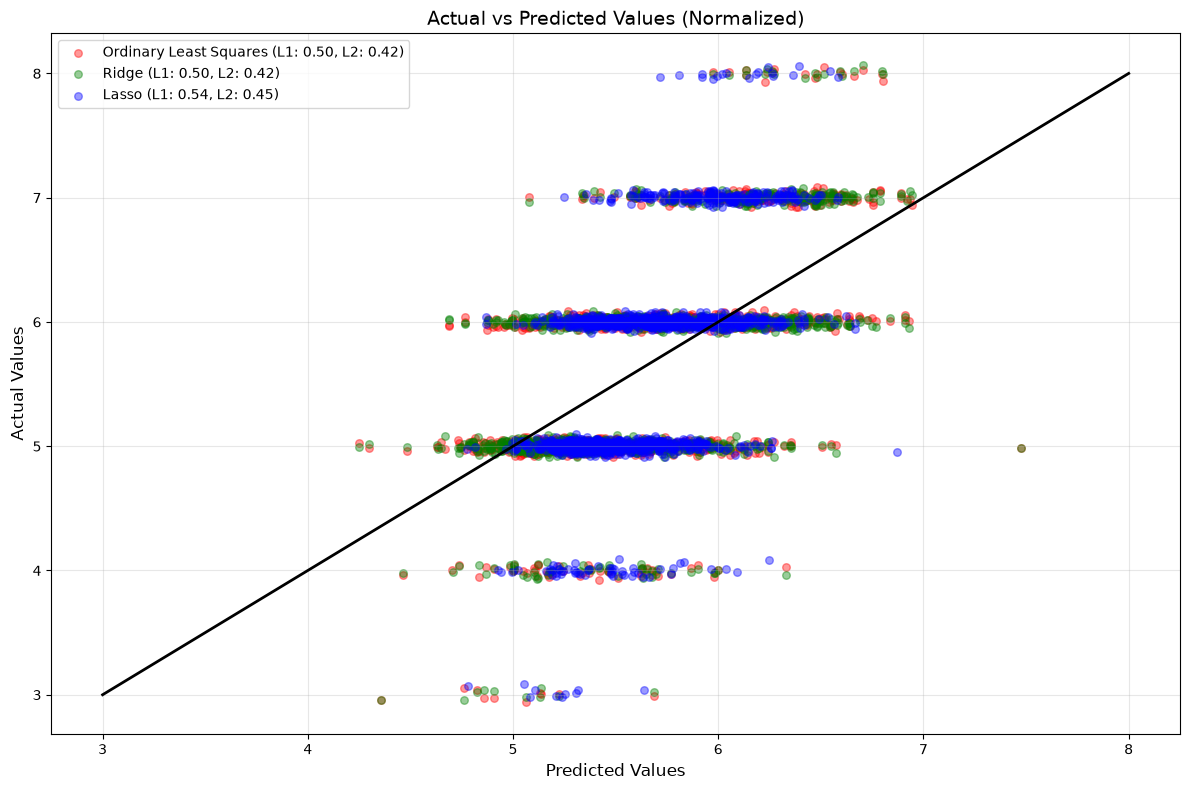

'\nLasso had a lower L2 error than before.\n'

In [11]:
# YOUR CODE HERE

# Defining models (with pipelines to normalize)
model_ols_norm = make_pipeline(StandardScaler(), sklearn.linear_model.LinearRegression())
model_ridge_norm = make_pipeline(StandardScaler(), sklearn.linear_model.Ridge(alpha=.5))
model_lasso_norm = make_pipeline(StandardScaler(), sklearn.linear_model.Lasso(alpha=0.1))

# Fitting
model_ols_norm.fit(df_input, df_target)
model_ridge_norm.fit(df_input, df_target)
model_lasso_norm.fit(df_input, df_target)

# Predicting
pred_ols_norm = model_ols_norm.predict(df_input)
pred_ridge_norm = model_ridge_norm.predict(df_input)
pred_lasso_norm = model_lasso_norm.predict(df_input)

# Losses
l2_ols_norm = sklearn.metrics.mean_squared_error(df_target, pred_ols_norm)
l1_ols_norm = sklearn.metrics.mean_absolute_error(df_target, pred_ols_norm)

l2_ridge_norm = sklearn.metrics.mean_squared_error(df_target, pred_ridge_norm)
l1_ridge_norm = sklearn.metrics.mean_absolute_error(df_target, pred_ridge_norm)

l2_lasso_norm = sklearn.metrics.mean_squared_error(df_target, pred_lasso_norm)
l1_lasso_norm = sklearn.metrics.mean_absolute_error(df_target, pred_lasso_norm)

# Plotting
plt.figure(figsize=(12, 8))

jitter_ols_norm = np.random.normal(0, 0.03, size=len(df_target))
jitter_ridge_norm = np.random.normal(0, 0.03, size=len(df_target))
jitter_lasso_norm = np.random.normal(0, 0.03, size=len(df_target))

plt.scatter(pred_ols_norm,
            df_target + jitter_ols_norm,
            alpha=0.4,
            s=30,
            color='red',
            label=f"Ordinary Least Squares (L1: {l1_ols_norm:.2f}, L2: {l2_ols_norm:.2f})"
)
plt.scatter(pred_ridge_norm,
            df_target + jitter_ridge_norm,
            alpha=0.4,
            s=30,
            color='green',
            label=f"Ridge (L1: {l1_ridge_norm:.2f}, L2: {l2_ridge_norm:.2f})"
)
plt.scatter(pred_lasso_norm,
            df_target + jitter_lasso_norm,
            alpha=0.4,
            s=30,
            color='blue',
            label=f"Lasso (L1: {l1_lasso_norm:.2f}, L2: {l2_lasso_norm:.2f})"
)

min_val = min(pred_ols_norm.min(), pred_ridge_norm.min(), pred_lasso_norm.min(), df_target.min())
max_val = max(pred_ols_norm.max(), pred_ridge_norm.max(), pred_lasso_norm.max(), df_target.max())
plt.plot([min_val, max_val], [min_val, max_val], lw=2, color='black')

plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Actual Values', fontsize=12)
plt.title('Actual vs Predicted Values (Normalized)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

############
# Analysis #
############

# Ordinary Least Squares
"""
Normalizing the dataset did not affect the L2 error for this model.
"""

# Ridge
"""
Ridge also performed the same with an identical L2 error.
"""

# Lasso
"""
Lasso had a lower L2 error than before.
"""

YOUR ANSWERS HERE

### Problem 9 (5 points)

A colleague suggests that you find better models by repeatedly building decision trees with random depth limits.
They say that trying 1000 such models will likely find an improvement as long as you use cross validation.
Give a one sentence response to this suggestion. 

In [12]:
# YOUR CODE HERE

"""
This is a bad approach because it will be computationally expensive and time consuming building and testing all models,
and furthermore we run the risk of severe overfitting.
"""

'\nThis is a bad approach because it will be computationally expensive and time consuming building and testing all models,\nand furthermore we run the risk of severe overfitting.\n'

YOUR ANSWERS HERE

### Problem 10 (10 points)

Pick a best model from all the models that you built and otherwise described in this project.
Explain how you picked it, including what criteria you chose, and how the other models compared by that criteria.
As much as possible, justify that problem in the context of the original data set. 

In [13]:
# YOUR CODE HERE

"""
The best model out of all the ones tested is a tie between ordinary least squares and ridge regression.

These two models performed, essentially, identically throughout all the different problems. Lasso regression
had a higher L1 and L2 in every case.

This dataset lends itself toward ordinary least squares and ridge regression due to the number of features and
significance of each feature. In our exploratory analysis we saw that alcohol had the strongest correlation with target,
but it still was not strong enough to be visually apparent. We can gather from this that there are not only a few features
that are relevant to the target, but rather many.
"""

'\nThe best model out of all the ones tested is a tie between ordinary least squares and ridge regression.\n\nThese two models performed, essentially, identically throughout all the different problems. Lasso regression\nhad a higher L1 and L2 in every case.\n\nThis dataset lends itself toward ordinary least squares and ridge regression due to the number of features and\nsignificance of each feature. In our exploratory analysis we saw that alcohol had the strongest correlation with target,\nbut it still was not strong enough to be visually apparent. We can gather from this that there are not only a few features\nthat are relevant to the target, but rather many.\n'

YOUR ANSWERS HERE